# Applied AI — Mid-Term Exam
## Super-Resolution GAN (SRGAN) for Dogs vs. Cats Classification

**Student:** Ramisa Farha (rfarha@charlotte.edu)
**Framework:** TensorFlow 2.x / Keras 3 on Google Colab (T4 GPU)
**Dataset:** [Dogs vs. Cats Classification (Kaggle)](https://www.kaggle.com/datasets/blourdhuraju/dogs-vs-cats-classification)
**Paper:** Ledig et al., *Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network* (CVPR 2017), arXiv:1609.04802

### Goal
Assignment 1 trained a MobileNetV2 transfer-learning classifier for cats vs. dogs. This notebook asks:
**if we throw away 15/16 of the pixels (128×128 → 32×32) and let an SRGAN reconstruct them (32×32 → 128×128), can a classifier trained on the reconstructed images match one trained on the real images?**

| Model | Trained on | Tested on |
|---|---|---|
| **Classifier A** | real images (128×128) | real test images (128×128) |
| **SRGAN** | pairs of low-res (32×32) → real (128×128), training split only | — |
| **Classifier B** | SRGAN-generated images (128×128) | SRGAN-generated test images (128×128) |

### Where each exam requirement is met
| Requirement | Section |
|---|---|
| Classifier A, transfer learning like Assignment 1, images downscaled to 128×128 | §3, §7 |
| SRGAN generating 128×128 from 32×32 | §8–§10 |
| Examples of scaled images | §4 |
| 70% training / 30% testing split | §5 |
| Normalization + image transformation, with samples shown | §6 |
| SRGAN trained ≥150 epochs | §10 (`SRGAN_EPOCHS = 150`) |
| Models saved every *n* epochs (resume after Colab disconnect) | §10 (`SAVE_EVERY = 5`), §7, §12 |
| Classifier B trained on SRGAN images | §11–§12 |
| Comparison with Accuracy, F1, AUC (+ precision, recall, ROC, confusion matrices) | §13 |

### How to run
1. `Runtime → Change runtime type → T4 GPU`.
2. Run **§0** and **§1**. Google Drive is **not** used (`USE_GOOGLE_DRIVE = False`); everything is saved in `/content/AppliedAI_Midterm_SRGAN`.
3. *(Recommended first)* set `SMOKE_TEST = True` in §1 and run everything (≈10 min). This checks the whole pipeline on a few hundred images.
4. Set `SMOKE_TEST = False` and `Runtime → Run all`.
5. **Colab deletes `/content` when the runtime disconnects.** The notebook keeps an up-to-date `/content/srgan_backup.zip` (checkpoints, finished models, results), rebuilt at every SRGAN checkpoint. Download it from the Files panel (or run §15) before a session ends. In the next session, upload `srgan_backup.zip` to `/content` **before** *Run all*; §1 unpacks it and every stage resumes where it stopped.

## 0. Environment

In [2]:
!nvidia-smi

Sun Oct 18 17:09:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os, io, sys, json, glob, time, math, random, hashlib, zipfile, shutil, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
import keras
from keras import layers, ops

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

warnings.filterwarnings("ignore", message="Truncated File Read")   # same non-fatal Pillow warning as Assignment 1

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU"))

# Let TensorFlow grow GPU memory instead of grabbing all of it up front.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("memory growth:", e)

Python     : 3.13.15
TensorFlow : 2.21.0
Keras      : 3.13.2
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Configuration and Storage

All settings live in this one cell. Everything is written under `OUTPUT_ROOT`. By default this is a local Colab folder (`/content/AppliedAI_Midterm_SRGAN`) and Google Drive is **not** mounted.

**Resuming without Google Drive.** Colab wipes `/content` when a runtime ends, so the notebook keeps a resume file, `/content/srgan_backup.zip`, holding the SRGAN checkpoint, finished models and results (≈0.5 GB). It is refreshed at every SRGAN checkpoint. Download it before the session ends. Next session, upload it to `/content` before running this cell; it is unpacked automatically. The resized-image cache is not in the zip because it is rebuilt from the Kaggle download in a few minutes.

*(Optional: set `USE_GOOGLE_DRIVE = True` to save straight to Drive instead. Resuming is then automatic.)*

**About `SRGAN_TRAIN_IMAGES`.** SRGAN training uses VGG19 feature losses on every step, so one epoch over all ~15k training images takes several minutes on a T4. 150 epochs over the full set would take well over one 12-hour Colab session. By default the SRGAN is trained on a random **5,000-image subset of the training split** (≈312 updates per epoch, ≈47k updates over 150 epochs), and the notebook prints the measured time per epoch and the ETA. Set it to `None` to use the full training split if you have the GPU time. The trained generator is then applied to **every** image (train and test) to create the dataset for Classifier B.

In [4]:
# ===================== MAIN SWITCH =====================
SMOKE_TEST = False          # True = quick end-to-end check on a few hundred images (~10 min)
# =======================================================

SEED = 42

# ---- image sizes (exam spec) ----
HR_SIZE = 128               # classifier / SRGAN output size (128x128)
LR_SIZE = 32                # SRGAN input size (32x32)
SCALE   = HR_SIZE // LR_SIZE   # 4x super-resolution, as in the paper

# ---- split (exam spec) ----
TEST_FRACTION = 0.30        # 70% train / 30% test
VAL_FRACTION_OF_TRAIN = 0.10   # 10% of the 70% is held out for early stopping (no test data is used for decisions)

# ---- SRGAN (paper settings unless noted) ----
SRGAN_TRAIN_IMAGES = 5000   # images from the training split used to train SRGAN (None = all)
SRGAN_BATCH = 16            # paper: 16
NUM_RES_BLOCKS = 16         # paper: B = 16
PRETRAIN_EPOCHS = 10        # SRResNet (MSE) warm-up used to initialise the GAN generator, as in the paper
SRGAN_EPOCHS = 150          # adversarial epochs (exam: at least 150)
LR_HIGH, LR_LOW = 1e-4, 1e-5   # paper: 1e-4 for first half of updates, 1e-5 for second half
ADV_WEIGHT = 1e-3           # paper: l_SR = l_VGG + 1e-3 * l_Gen
VGG_RESCALE = 1.0 / 12.75   # paper: VGG feature maps rescaled by 1/12.75
SAVE_EVERY = 5              # save SRGAN checkpoint every n epochs

# ---- classifiers (same recipe as Assignment 1, at 128x128) ----
CLF_BATCH = 32
INITIAL_EPOCHS = 5
FINE_TUNE_EPOCHS = 5
INITIAL_LR = 1e-3
FINE_TUNE_LR = 1e-5
FINE_TUNE_LAST_N = 30

MAX_IMAGES = None           # None = use all images in the dataset

if SMOKE_TEST:
    MAX_IMAGES = 600
    SRGAN_TRAIN_IMAGES = 200
    PRETRAIN_EPOCHS = 1
    SRGAN_EPOCHS = 2
    SAVE_EVERY = 1
    INITIAL_EPOCHS = 1
    FINE_TUNE_EPOCHS = 1

# ---- storage ----
USE_GOOGLE_DRIVE = False    # False = no Drive; save in /content and use srgan_backup.zip to resume
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/AppliedAI_Midterm_SRGAN"
elif IN_COLAB:
    BASE = "/content/AppliedAI_Midterm_SRGAN"
else:
    BASE = os.path.abspath("./outputs")
_bk = "srgan_backup_smoke.zip" if SMOKE_TEST else "srgan_backup.zip"     # smoke-test progress never mixes with the real run
BACKUP_ZIP = os.path.join("/content", _bk) if IN_COLAB else os.path.join(BASE, _bk)

OUTPUT_ROOT = os.path.join(BASE, "smoke_test" if SMOKE_TEST else "full_run")
CACHE_DIR   = os.path.join(OUTPUT_ROOT, "cache")
SRGAN_DIR   = os.path.join(OUTPUT_ROOT, "checkpoints", "srgan")
MODEL_DIR   = os.path.join(OUTPUT_ROOT, "models")
RESULTS_DIR = os.path.join(OUTPUT_ROOT, "results")
for d in [CACHE_DIR, SRGAN_DIR, MODEL_DIR, RESULTS_DIR, os.path.join(RESULTS_DIR, "srgan_progress")]:
    os.makedirs(d, exist_ok=True)

# ---- resume from an uploaded backup (no-Drive mode) ----
if os.path.exists(BACKUP_ZIP) and not os.path.exists(os.path.join(SRGAN_DIR, "state.json")):
    with zipfile.ZipFile(BACKUP_ZIP) as zf:
        zf.extractall(OUTPUT_ROOT)
    print("Restored previous progress from", BACKUP_ZIP)

def make_backup():
    # Zip everything needed to resume (not the image caches, which are rebuilt from Kaggle).
    keep_srgan = {"state.json", "generator_latest.weights.h5", "discriminator_latest.weights.h5",
                  "generator_srresnet_pretrained.weights.h5", "g_opt.npz", "d_opt.npz", "pre_opt.npz"}
    final_models = {"classifier_A.keras", "classifier_B.keras", "srgan_generator.weights.h5"}
    tmp = BACKUP_ZIP + ".tmp"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_STORED) as zf:
        for root, _, files in os.walk(OUTPUT_ROOT):
            for fname in files:
                full = os.path.join(root, fname)
                rel = os.path.relpath(full, OUTPUT_ROOT)
                top = rel.split(os.sep)[0]
                if (top == "results" or (top == "checkpoints" and fname in keep_srgan)
                        or (top == "models" and fname in final_models)):
                    zf.write(full, rel)
    os.replace(tmp, BACKUP_ZIP)
    print(f"  backup refreshed -> {BACKUP_ZIP} ({os.path.getsize(BACKUP_ZIP)/1e6:.0f} MB)")

keras.utils.set_random_seed(SEED)     # seeds Python, NumPy and TensorFlow
CLASS_NAMES = ["Cat", "Dog"]          # label 0 = cat, 1 = dog (same as Assignment 1)
AUTOTUNE = tf.data.AUTOTUNE

def savefig(name):
    path = os.path.join(RESULTS_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("saved ->", path)

print("SMOKE_TEST :", SMOKE_TEST)
print("OUTPUT_ROOT:", OUTPUT_ROOT)

SMOKE_TEST : False
OUTPUT_ROOT: /content/AppliedAI_Midterm_SRGAN/full_run


## 2. Download the Dataset

The dataset is downloaded with `kagglehub` (pre-installed in Colab; public datasets do not need a Kaggle login).
If the download fails, upload the dataset ZIP from Kaggle into `/content` with the Colab Files panel and re-run the cell — the cell falls back to any ZIP it finds there (same approach as Assignment 1).

This step is skipped automatically once the resized image cache from §3 exists (i.e. later in the same session).

In [5]:
KAGGLE_DATASET = "blourdhuraju/dogs-vs-cats-classification"
CACHE_FILE = os.path.join(CACHE_DIR, f"images_{HR_SIZE}_{LR_SIZE}.npz")

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def find_images(root):
    return sorted(str(p) for p in Path(root).rglob("*") if p.suffix.lower() in IMAGE_EXTS)

def extract_zips(root, dest):
    for z in sorted(Path(root).rglob("*.zip")):
        out = os.path.join(dest, z.stem)
        if not os.path.exists(out):
            print("extracting", z)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(out)

DATA_ROOT = None
if os.path.exists(CACHE_FILE):
    print("Image cache found — download not needed:", CACHE_FILE)
else:
    try:
        import kagglehub
        DATA_ROOT = kagglehub.dataset_download(KAGGLE_DATASET)
        print("Downloaded with kagglehub to:", DATA_ROOT)
    except Exception as e:
        print("kagglehub download failed:", repr(e))
        zips = sorted(glob.glob("/content/*.zip"))
        if not zips:
            raise FileNotFoundError(
                "Could not download from Kaggle and no ZIP was found in /content. "
                "Download the dataset ZIP from " + "https://www.kaggle.com/datasets/" + KAGGLE_DATASET +
                ", upload it to /content with the Files panel, and re-run this cell.")
        DATA_ROOT = "/content/dataset_extracted"
        os.makedirs(DATA_ROOT, exist_ok=True)
        for z in zips:
            print("extracting", z)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(DATA_ROOT)

    if not find_images(DATA_ROOT):          # dataset shipped as nested ZIPs
        extract_zips(DATA_ROOT, "/content/dataset_nested")
        DATA_ROOT = "/content/dataset_nested"
    print("Image files found:", len(find_images(DATA_ROOT)))

Using Colab cache for faster access to the 'dogs-vs-cats-classification' dataset.
Downloaded with kagglehub to: /kaggle/input/dogs-vs-cats-classification
Image files found: 24930


## 3. Label, De-duplicate and Downscale Every Image to 128×128

* **Labels** come from the filename (`cat.123.jpg`, `dog_45.jpg`) or a parent folder (`cats/`, `dogs/`), exactly like Assignment 1. The archive's own train/validation/test folders are ignored and all labelled images are pooled, so the 70/30 split in §5 is made by this notebook.
* **Duplicates** (byte-identical files that appear in more than one folder) are removed using an MD5 hash, so the same picture can never be in both the training and the test set.
* Each image is **downscaled to 128×128** (bicubic, anti-aliased) — the input size for Classifier A and the target size for SRGAN.
* Each 128×128 image is then **downscaled by 4× to 32×32** with a bicubic kernel. This is how the paper creates its low-resolution inputs.

The result is cached as `uint8` arrays, so re-running cells in the same session loads it in seconds.

In [6]:
def infer_label(path):
    name = os.path.basename(path).lower()
    if name.startswith(("cat.", "cat_", "cat-")): return 0
    if name.startswith(("dog.", "dog_", "dog-")): return 1
    for part in reversed([p.lower() for p in Path(path).parts[:-1]]):
        if part in ("cat", "cats"): return 0
        if part in ("dog", "dogs"): return 1
    return None

def load_and_resize(path):
    try:
        with open(path, "rb") as f:
            data = f.read()
        digest = hashlib.md5(data).hexdigest()
        img = Image.open(io.BytesIO(data)).convert("RGB")
        orig_size = img.size
        hr = img.resize((HR_SIZE, HR_SIZE), Image.BICUBIC)           # 128x128
        lr = hr.resize((LR_SIZE, LR_SIZE), Image.BICUBIC)            # 32x32  (4x bicubic downsampling)
        return digest, np.asarray(hr, np.uint8), np.asarray(lr, np.uint8), orig_size
    except Exception as e:
        return None

if os.path.exists(CACHE_FILE):
    cache = np.load(CACHE_FILE, allow_pickle=False)
    X_hr, X_lr, y_all = cache["X_hr"], cache["X_lr"], cache["y"]
    paths, orig_sizes = cache["paths"], cache["orig_sizes"]
    print("Loaded cache:", CACHE_FILE)
else:
    all_files = find_images(DATA_ROOT)
    labelled = [(p, infer_label(p)) for p in all_files]
    labelled = [(p, l) for p, l in labelled if l is not None]
    print(f"Files found: {len(all_files):,}   labelled cat/dog: {len(labelled):,}")

    if MAX_IMAGES is not None and len(labelled) > MAX_IMAGES:      # smoke test: stratified random subset
        lab_paths = [p for p, _ in labelled]
        lab_y = [l for _, l in labelled]
        lab_paths, _, lab_y, _ = train_test_split(lab_paths, lab_y, train_size=MAX_IMAGES,
                                                  stratify=lab_y, random_state=SEED)
        labelled = sorted(zip(lab_paths, lab_y))

    with ThreadPoolExecutor(max_workers=16) as pool:
        results = list(tqdm(pool.map(load_and_resize, [p for p, _ in labelled]),
                            total=len(labelled), desc="resizing"))

    seen, keep, conflicts = {}, [], set()
    n_bad = n_dup = 0
    for (p, l), r in zip(labelled, results):
        if r is None:
            n_bad += 1; continue
        if r[0] in seen:
            n_dup += 1
            if seen[r[0]] != l: conflicts.add(r[0])      # same picture filed under both cat and dog
            continue
        seen[r[0]] = l; keep.append((p, l, r))
    keep = [k for k in keep if k[2][0] not in conflicts]   # drop pictures with contradictory labels
    print(f"Unreadable images skipped: {n_bad}   duplicate images removed: {n_dup}   "
          f"images with conflicting cat/dog labels removed: {len(conflicts)}")

    X_hr = np.stack([r[1] for _, _, r in keep])
    X_lr = np.stack([r[2] for _, _, r in keep])
    y_all = np.array([l for _, l, _ in keep], np.int64)
    paths = np.array([p for p, _, _ in keep])
    orig_sizes = np.array([r[3] for _, _, r in keep], np.int32)
    del results, keep

    tmp = CACHE_FILE + ".tmp.npz"
    np.savez(tmp, X_hr=X_hr, X_lr=X_lr, y=y_all, paths=paths, orig_sizes=orig_sizes)
    os.replace(tmp, CACHE_FILE)
    print("Saved cache:", CACHE_FILE)

print(f"\nTotal images: {len(y_all):,}   cats: {(y_all==0).sum():,}   dogs: {(y_all==1).sum():,}")
print("HR array:", X_hr.shape, X_hr.dtype, " | LR array:", X_lr.shape, X_lr.dtype)

Files found: 24,930   labelled cat/dog: 24,930


resizing:   0%|          | 0/24930 [00:00<?, ?it/s]

Unreadable images skipped: 0   duplicate images removed: 0   images with conflicting cat/dog labels removed: 0
Saved cache: /content/AppliedAI_Midterm_SRGAN/full_run/cache/images_128_32.npz

Total images: 24,930   cats: 12,472   dogs: 12,458
HR array: (24930, 128, 128, 3) uint8  | LR array: (24930, 32, 32, 3) uint8


## 4. Examples of the Scaled Images

Each row shows one image at three scales: the **original** file, the **128×128** version used by Classifier A and as the SRGAN target, and the **32×32** version given to the SRGAN. The 32×32 image is drawn with nearest-neighbour enlargement so its real pixel grid is visible.

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/01_scaled_examples.png


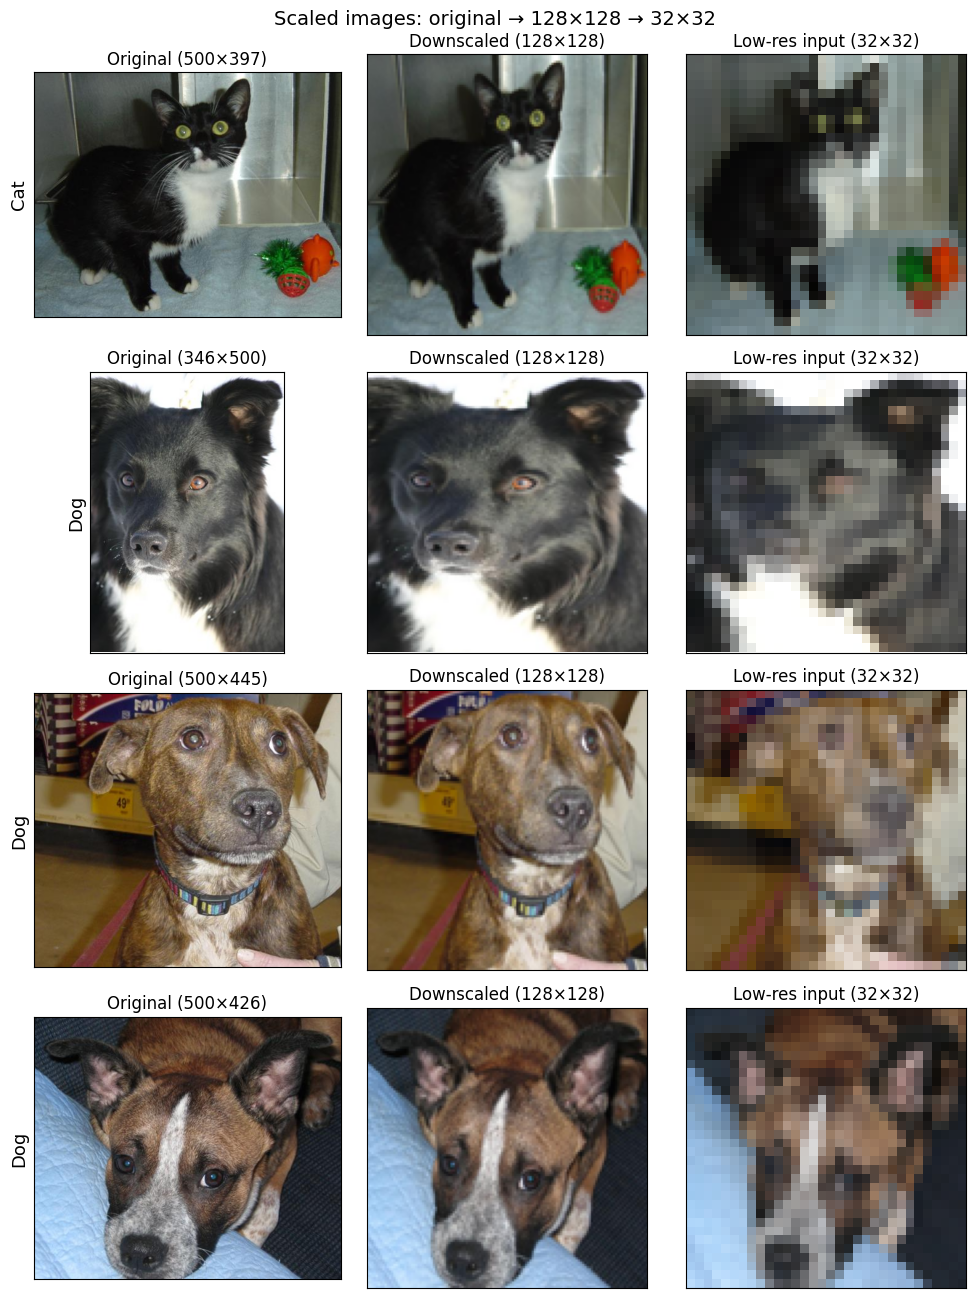

In [7]:
rng = np.random.default_rng(SEED)
show_idx = rng.choice(len(y_all), 4, replace=False)

fig, axes = plt.subplots(len(show_idx), 3, figsize=(10, 3.3 * len(show_idx)))
for row, i in enumerate(show_idx):
    w, h = orig_sizes[i]
    try:
        orig = Image.open(str(paths[i])).convert("RGB")
    except Exception:                       # original files are gone in a new session; fall back to 128x128
        orig = Image.fromarray(X_hr[i])
    axes[row, 0].imshow(orig);                        axes[row, 0].set_title(f"Original ({w}×{h})")
    axes[row, 1].imshow(X_hr[i]);                     axes[row, 1].set_title(f"Downscaled ({HR_SIZE}×{HR_SIZE})")
    axes[row, 2].imshow(X_lr[i], interpolation="nearest"); axes[row, 2].set_title(f"Low-res input ({LR_SIZE}×{LR_SIZE})")
    axes[row, 0].set_ylabel(CLASS_NAMES[y_all[i]], fontsize=13)
    for a in axes[row]:
        a.set_xticks([]); a.set_yticks([])
plt.suptitle("Scaled images: original → 128×128 → 32×32", fontsize=14)
plt.tight_layout()
savefig("01_scaled_examples.png")
plt.show()

## 5. 70% Training / 30% Testing Split

A stratified 70/30 split keeps the cat/dog balance in both parts. The **same indices** are used for every model, so Classifier A and Classifier B see exactly the same pictures, only at different image quality.

Inside the 70% training part, 10% is held out as a **validation** set for early stopping and learning-rate decisions. The SRGAN is trained only on the remaining training images, so the 30% test set is never touched until final evaluation.

| Part | Share of all images | Used for |
|---|---|---|
| `train` | 63% | Classifier A / B weights, SRGAN training |
| `val` | 7% | early stopping, SRGAN progress monitoring |
| `test` | 30% | final comparison only |

In [8]:
all_idx = np.arange(len(y_all))
trainval_idx, test_idx = train_test_split(all_idx, test_size=TEST_FRACTION,
                                          stratify=y_all, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=VAL_FRACTION_OF_TRAIN,
                                      stratify=y_all[trainval_idx], random_state=SEED)

assert len(set(train_idx) & set(test_idx)) == 0 and len(set(val_idx) & set(test_idx)) == 0
assert len(set(train_idx) & set(val_idx)) == 0
assert len(train_idx) + len(val_idx) + len(test_idx) == len(y_all)

split_table = pd.DataFrame({
    "images": [len(train_idx), len(val_idx), len(test_idx)],
    "cats":   [(y_all[train_idx]==0).sum(), (y_all[val_idx]==0).sum(), (y_all[test_idx]==0).sum()],
    "dogs":   [(y_all[train_idx]==1).sum(), (y_all[val_idx]==1).sum(), (y_all[test_idx]==1).sum()],
}, index=["train", "val", "test"])
split_table["share"] = (split_table["images"] / len(y_all)).map("{:.1%}".format)
split_table.to_csv(os.path.join(RESULTS_DIR, "split_counts.csv"))
print(f"Training part (train+val): {len(trainval_idx):,} = {len(trainval_idx)/len(y_all):.1%}")
print(f"Testing part             : {len(test_idx):,} = {len(test_idx)/len(y_all):.1%}\n")
split_table

Training part (train+val): 17,451 = 70.0%
Testing part             : 7,479 = 30.0%



,images,cats,dogs,share
train,15705,7857,7848,63.0%
val,1746,873,873,7.0%
test,7479,3742,3737,30.0%


## 6. Normalization and Image Transformation

**Normalization.** MobileNetV2 expects pixels in **[-1, 1]**, so each 0–255 pixel value *x* becomes *x* / 127.5 − 1 (this is what `mobilenet_v2.preprocess_input` does). For the SRGAN, the paper scales low-res inputs to **[0, 1]** and high-res targets to **[-1, 1]**; the same scaling is used in §9.

**Transformation (training only).** The same augmentations as Assignment 1's `ImageDataGenerator` — rotation ±20°, width/height shift ±10%, zoom ±15%, horizontal flip — now written as Keras preprocessing layers inside a `tf.data` pipeline. Validation and test images are only normalized, never augmented.

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/02_transformed_samples.png


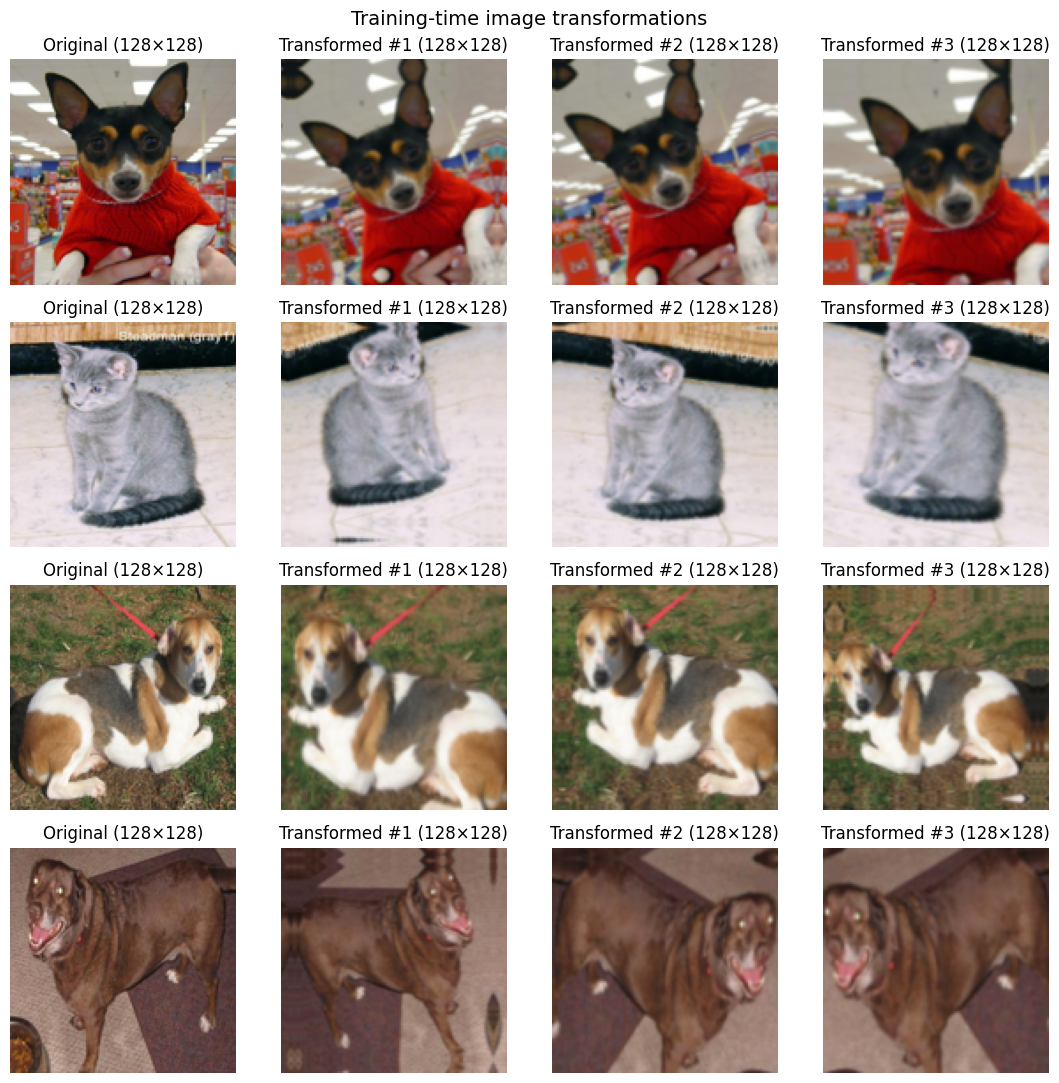

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/03_normalized_batch.png


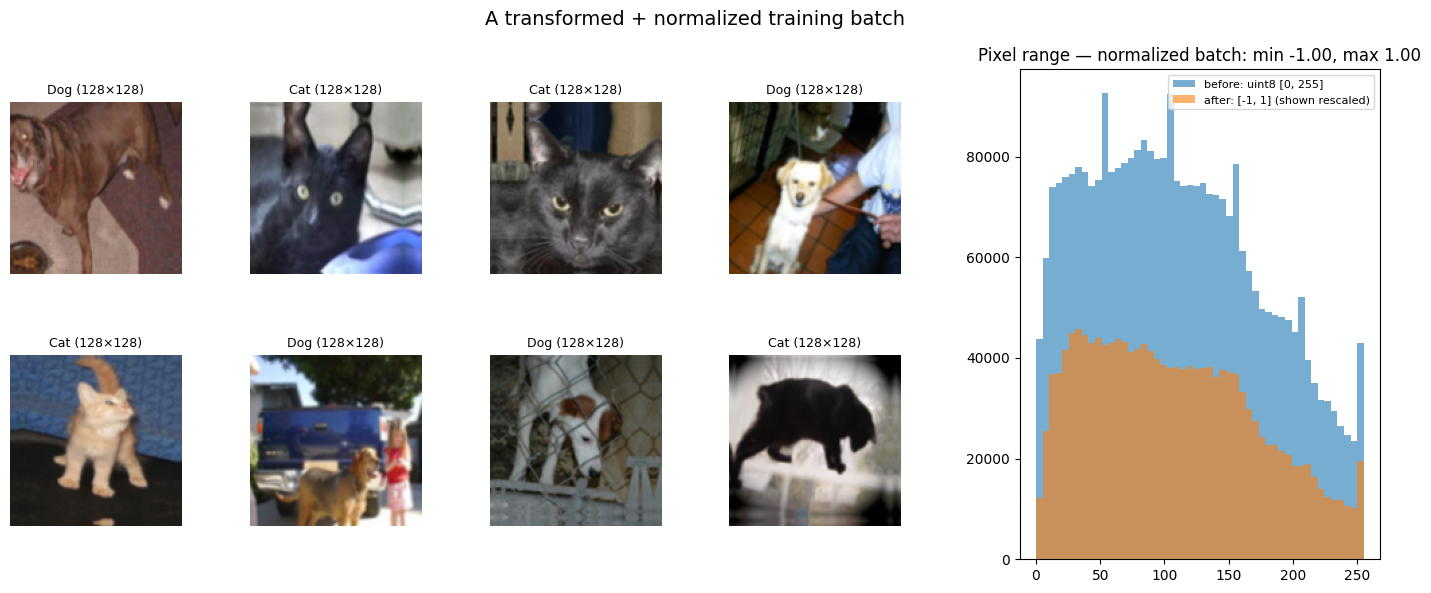

Batch shape: (32, 128, 128, 3)  value range: -1.0 to 1.0


In [9]:
augmenter = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(20 / 360, fill_mode="reflect"),
    layers.RandomTranslation(0.10, 0.10, fill_mode="reflect"),
    layers.RandomZoom(0.15, fill_mode="reflect"),
], name="augmentation")

def normalize(x):                       # uint8 [0,255] -> float [-1,1] (MobileNetV2 preprocessing)
    return tf.cast(x, tf.float32) / 127.5 - 1.0

def make_clf_dataset(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype(np.float32)))
    if training:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(CLF_BATCH)
    ds = ds.map(lambda x, t: (tf.cast(x, tf.float32), t), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(lambda x, t: (augmenter(x, training=True), t), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, t: (x / 127.5 - 1.0, t), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

# ---- demonstrate: original vs. 3 random transformations, all at 128x128 ----
demo = X_hr[train_idx[:4]]
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for r in range(4):
    axes[r, 0].imshow(demo[r]); axes[r, 0].set_title(f"Original ({HR_SIZE}×{HR_SIZE})")
    for c in range(1, 4):
        aug = augmenter(tf.cast(demo[r:r+1], tf.float32), training=True)[0].numpy()
        axes[r, c].imshow(np.clip(aug, 0, 255).astype(np.uint8)); axes[r, c].set_title(f"Transformed #{c} ({HR_SIZE}×{HR_SIZE})")
    for a in axes[r]: a.axis("off")
plt.suptitle("Training-time image transformations", fontsize=14)
plt.tight_layout(); savefig("02_transformed_samples.png"); plt.show()

# ---- demonstrate: what the network actually receives after normalization ----
xb, yb = next(iter(make_clf_dataset(X_hr[train_idx[:64]], y_all[train_idx[:64]], training=True)))
xb = xb.numpy()
fig = plt.figure(figsize=(14, 6))
for i in range(8):
    ax = fig.add_subplot(2, 6, (i // 4) * 6 + i % 4 + 1)
    ax.imshow((xb[i] + 1) / 2); ax.set_title(CLASS_NAMES[int(yb[i])] + f" ({HR_SIZE}×{HR_SIZE})", fontsize=9); ax.axis("off")
ax = fig.add_subplot(1, 3, 3)
ax.hist(X_hr[train_idx[:64]].ravel(), bins=50, alpha=0.6, label="before: uint8 [0, 255]")
ax.hist(xb.ravel() * 127.5 + 127.5, bins=50, alpha=0.6, label="after: [-1, 1] (shown rescaled)")
ax.set_title(f"Pixel range — normalized batch: min {xb.min():.2f}, max {xb.max():.2f}")
ax.legend(fontsize=8)
plt.suptitle("A transformed + normalized training batch", fontsize=14)
plt.tight_layout(); savefig("03_normalized_batch.png"); plt.show()
print("Batch shape:", xb.shape, " value range:", xb.min().round(3), "to", xb.max().round(3))

## 7. Classifier A — Transfer Learning on Real 128×128 Images

The classifier is built exactly like Assignment 1, at 128×128 instead of 160×160:

1. **MobileNetV2** with ImageNet weights, frozen → global average pooling → dropout 0.2 → one sigmoid neuron. Trained 5 epochs with Adam (1e-3).
2. **Fine-tuning:** the last 30 MobileNetV2 layers are unfrozen (batch-norm layers stay frozen) and trained 5 more epochs with Adam (1e-5).
3. `EarlyStopping` (patience 2, best weights restored) and `ReduceLROnPlateau` watch validation loss.

**Saving:** the model is saved after **every epoch** (`*_last.keras`) and whenever validation loss improves (`*_best.keras`); the final model is `classifier_A.keras`. If that file already exists, training is skipped and the saved model is loaded.

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

=== classifier_A: stage 1 — frozen MobileNetV2 ===
Epoch 1/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 84s 145ms/step - accuracy: 0.9358 - auc: 0.9849 - loss: 0.1580 - val_accuracy: 0.9748 - val_auc: 0.9975 - val_loss: 0.0654 - learning_rate: 0.0010
Epoch 2/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 59s 120ms/step - accuracy: 0.9541 - auc: 0.9915 - loss: 0.1161 - val_accuracy: 0.9777 - val_auc: 0.9979 - val_loss: 0.0602 - learning_rate: 0.0010
Epoch 3/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 60s 121ms/step - accuracy: 0.9589 - auc: 0.9923 - loss: 0.1078 - val_accuracy: 0.9782 - val_auc: 0.9981 - val_loss: 0.0581 - learning_rate: 0.0010
Epoch 4/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 81s 120ms/step - accuracy: 0.9589 - auc: 0.9932 - loss: 0.1044 - val_accuracy: 0.9788 - val_auc: 0.9977 - val_loss: 0.0605 - learning_rate: 0.0010
Epoch 5/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 82s 120ms/step - accuracy: 0.9621 - auc: 0.9938 - loss: 0.0977 - val_accuracy: 0.9759 - val_auc: 0.9979 - val_loss: 

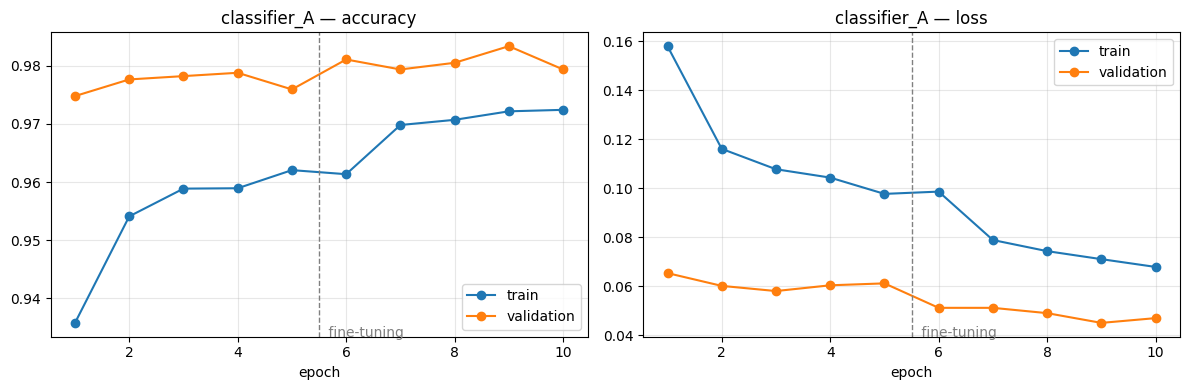

In [10]:
def build_classifier():
    base = keras.applications.MobileNetV2(input_shape=(HR_SIZE, HR_SIZE, 3),
                                          include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape=(HR_SIZE, HR_SIZE, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs), base

def clf_callbacks(tag, stage):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=1, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, f"{tag}_{stage}_last.keras")),          # every epoch
        keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, f"{tag}_{stage}_best.keras"),
                                        monitor="val_loss", save_best_only=True),
        keras.callbacks.CSVLogger(os.path.join(RESULTS_DIR, f"{tag}_{stage}_log.csv")),
    ]

def train_classifier(tag, X_train, y_train, X_val, y_val):
    final_path = os.path.join(MODEL_DIR, f"{tag}.keras")
    if os.path.exists(final_path):
        print(f"{tag}: found {final_path} — loading instead of retraining.")
        return keras.models.load_model(final_path), None

    keras.utils.set_random_seed(SEED)
    train_ds = make_clf_dataset(X_train, y_train, training=True)
    val_ds = make_clf_dataset(X_val, y_val, training=False)
    model, base = build_classifier()

    model.compile(optimizer=keras.optimizers.Adam(INITIAL_LR), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    print(f"\n=== {tag}: stage 1 — frozen MobileNetV2 ===")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=INITIAL_EPOCHS,
                   callbacks=clf_callbacks(tag, "stage1"))

    base.trainable = True
    for layer in base.layers[:-FINE_TUNE_LAST_N]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    print("Trainable MobileNetV2 layers:", sum(l.trainable for l in base.layers))

    model.compile(optimizer=keras.optimizers.Adam(FINE_TUNE_LR), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    print(f"\n=== {tag}: stage 2 — fine-tuning ===")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
                   callbacks=clf_callbacks(tag, "stage2"))

    model.save(final_path)
    print("saved ->", final_path)
    make_backup()
    return model, (h1.history, h2.history)

def plot_clf_history(hist, tag):
    if hist is None:
        logs = [os.path.join(RESULTS_DIR, f"{tag}_{s}_log.csv") for s in ("stage1", "stage2")]
        if not all(os.path.exists(p) for p in logs):
            print("No training history available for", tag); return
        hist = [pd.read_csv(p).to_dict("list") for p in logs]
    h = {k: list(hist[0][k]) + list(hist[1][k]) for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
    n1 = len(hist[0]["loss"])
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, key in zip(ax, ("accuracy", "loss")):
        a.plot(range(1, len(h[key]) + 1), h[key], "o-", label="train")
        a.plot(range(1, len(h[key]) + 1), h["val_" + key], "o-", label="validation")
        a.axvline(n1 + 0.5, color="gray", ls="--", lw=1); a.text(n1 + 0.6, a.get_ylim()[0], " fine-tuning", color="gray")
        a.set_xlabel("epoch"); a.set_title(f"{tag} — {key}"); a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); savefig(f"{tag}_training_curves.png"); plt.show()

clf_A, hist_A = train_classifier("classifier_A",
                                 X_hr[train_idx], y_all[train_idx],
                                 X_hr[val_idx], y_all[val_idx])
plot_clf_history(hist_A, "classifier_A")

## 8. SRGAN Architecture (Ledig et al., Fig. 4)

**Generator** (input 32×32, output 128×128):
* 9×9 conv, 64 filters, PReLU
* 16 residual blocks: (3×3 conv 64 → BN → PReLU → 3×3 conv 64 → BN) + skip
* 3×3 conv 64 → BN, plus a long skip from the first layer
* 2 upsampling blocks: 3×3 conv 256 → **PixelShuffle ×2** (sub-pixel convolution) → PReLU, giving 32→64→128
* 9×9 conv, 3 filters, tanh (output in [-1, 1])

**Discriminator** (input 128×128):
* 3×3 conv 64 → LeakyReLU(0.2)
* 7 blocks of 3×3 conv → BN → LeakyReLU(0.2) with filters/strides 64/2, 128/1, 128/2, 256/1, 256/2, 512/1, 512/2
* Dense 1024 → LeakyReLU(0.2) → Dense 1 (the sigmoid is folded into the loss with `from_logits=True`, which is numerically safer but mathematically identical)

**Feature extractor for the content loss:** VGG19 (ImageNet), output of `block5_conv4` after its ReLU — the paper's **VGG54** loss.

In [11]:
@keras.saving.register_keras_serializable(package="srgan")
class PixelShuffle(layers.Layer):
    # Sub-pixel convolution rearrangement (Shi et al., 2016): (H, W, C*r*r) -> (H*r, W*r, C)
    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale
    def call(self, x):
        r = self.scale
        h, w, c = x.shape[1], x.shape[2], x.shape[3]
        c_out = c // (r * r)
        x = ops.reshape(x, (-1, h, w, r, r, c_out))
        x = ops.transpose(x, (0, 1, 3, 2, 4, 5))
        return ops.reshape(x, (-1, h * r, w * r, c_out))
    def compute_output_shape(self, s):
        r = self.scale
        return (s[0], s[1] * r, s[2] * r, s[3] // (r * r))
    def get_config(self):
        return {**super().get_config(), "scale": self.scale}

def build_generator(num_res_blocks=NUM_RES_BLOCKS):
    lr_in = keras.Input(shape=(LR_SIZE, LR_SIZE, 3), name="lr_0_1")
    x = layers.Conv2D(64, 9, padding="same")(lr_in)
    x = layers.PReLU(shared_axes=[1, 2])(x)
    skip = x
    for _ in range(num_res_blocks):
        r = layers.Conv2D(64, 3, padding="same")(x)
        r = layers.BatchNormalization(momentum=0.9)(r)
        r = layers.PReLU(shared_axes=[1, 2])(r)
        r = layers.Conv2D(64, 3, padding="same")(r)
        r = layers.BatchNormalization(momentum=0.9)(r)
        x = layers.Add()([x, r])
    x = layers.Conv2D(64, 3, padding="same")(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Add()([x, skip])
    for _ in range(int(math.log2(SCALE))):          # 2 blocks for 4x
        x = layers.Conv2D(256, 3, padding="same")(x)
        x = PixelShuffle(2)(x)
        x = layers.PReLU(shared_axes=[1, 2])(x)
    sr_out = layers.Conv2D(3, 9, padding="same", activation="tanh", name="sr_m1_1")(x)
    return keras.Model(lr_in, sr_out, name="generator")

def build_discriminator():
    hr_in = keras.Input(shape=(HR_SIZE, HR_SIZE, 3), name="hr_m1_1")
    x = layers.Conv2D(64, 3, padding="same")(hr_in)
    x = layers.LeakyReLU(0.2)(x)
    for filters, stride in [(64, 2), (128, 1), (128, 2), (256, 1), (256, 2), (512, 1), (512, 2)]:
        x = layers.Conv2D(filters, 3, strides=stride, padding="same")(x)
        x = layers.BatchNormalization(momentum=0.9)(x)
        x = layers.LeakyReLU(0.2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(1024)(x)
    x = layers.LeakyReLU(0.2)(x)
    logit = layers.Dense(1, name="real_logit")(x)
    return keras.Model(hr_in, logit, name="discriminator")

def build_vgg54():
    vgg = keras.applications.VGG19(include_top=False, weights="imagenet",
                                   input_shape=(HR_SIZE, HR_SIZE, 3))
    vgg.trainable = False
    return keras.Model(vgg.input, vgg.get_layer("block5_conv4").output, name="vgg54")

generator = build_generator()
discriminator = build_discriminator()
vgg54 = build_vgg54()

print(f"Generator params    : {generator.count_params():,}")
print(f"Discriminator params: {discriminator.count_params():,}")
print("Generator   :", generator.input_shape, "->", generator.output_shape)
print("Discriminator:", discriminator.input_shape, "->", discriminator.output_shape)
print("VGG54        :", vgg54.input_shape, "->", vgg54.output_shape)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Generator params    : 1,554,883
Discriminator params: 38,249,281
Generator   : (None, 32, 32, 3) -> (None, 128, 128, 3)
Discriminator: (None, 128, 128, 3) -> (None, 1)
VGG54        : (None, 128, 128, 3) -> (None, 8, 8, 512)


## 9. SRGAN Losses, Data Pipeline and Checkpointing

**Perceptual loss** (paper Eq. 3): `l_SR = l_VGG54 + 10⁻³ · l_Gen`
* `l_VGG54` — mean squared error between VGG19 `block5_conv4` features of the real and generated images, features rescaled by 1/12.75 (paper §3.2).
* `l_Gen` — −log D(G(LR)), i.e. binary cross-entropy of the discriminator's verdict on fake images against the "real" label (paper Eq. 6).
* Discriminator loss — standard GAN cross-entropy on real (label 1) and generated (label 0) images (paper Eq. 2).

**Training schedule** (paper §3.2, scaled to this dataset):
1. *SRResNet warm-up:* the generator alone is trained with pixel MSE for `PRETRAIN_EPOCHS` epochs, which the paper uses to avoid poor local optima.
2. *Adversarial training:* `SRGAN_EPOCHS = 150` epochs, generator and discriminator updated alternately on every batch (k = 1), Adam (β₁ = 0.9), learning rate 1e-4 for the first half and 1e-5 for the second half.

**Data:** low-res inputs scaled to [0, 1], high-res targets to [-1, 1] (paper §3.2). Each LR/HR pair is flipped horizontally together at random.

**Checkpointing every `SAVE_EVERY` epochs** (and a refreshed `srgan_backup.zip`): generator and discriminator weights, both optimizers' internal state (Adam moments), the epoch counter and the loss history. Files are written to a temporary name and then renamed, so a disconnect in the middle of a save cannot corrupt the last good checkpoint. A copy of the generator is also kept for every checkpointed epoch (`generator_epoch_XXX.weights.h5`, ~6 MB each).

In [12]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)
VGG_MEAN_BGR = tf.constant([103.939, 116.779, 123.68], tf.float32)

def vgg_features(img_m1_1):
    x = (img_m1_1 + 1.0) * 127.5                 # [-1,1] -> [0,255] RGB
    x = x[..., ::-1] - VGG_MEAN_BGR              # VGG19 "caffe" preprocessing (BGR, mean subtracted)
    return vgg54(x, training=False) * VGG_RESCALE

def content_loss(hr, sr):
    return tf.reduce_mean(tf.square(vgg_features(hr) - vgg_features(sr)))

# ---------- SRGAN training data: training split only ----------
rng = np.random.default_rng(SEED)
if SRGAN_TRAIN_IMAGES is not None and SRGAN_TRAIN_IMAGES < len(train_idx):
    srgan_idx = rng.choice(train_idx, SRGAN_TRAIN_IMAGES, replace=False)
else:
    srgan_idx = np.array(train_idx)
monitor_idx = val_idx[:64]                       # fixed validation images for PSNR/SSIM + progress figures
assert len(set(srgan_idx) & set(test_idx)) == 0

def to_lr_float(x): return tf.cast(x, tf.float32) / 255.0          # [0,1]
def to_hr_float(x): return tf.cast(x, tf.float32) / 127.5 - 1.0    # [-1,1]

def random_pair_flip(lr, hr):
    flip = tf.random.uniform(()) > 0.5
    lr = tf.cond(flip, lambda: tf.image.flip_left_right(lr), lambda: lr)
    hr = tf.cond(flip, lambda: tf.image.flip_left_right(hr), lambda: hr)
    return lr, hr

srgan_ds = (tf.data.Dataset.from_tensor_slices((X_lr[srgan_idx], X_hr[srgan_idx]))
            .shuffle(len(srgan_idx), seed=SEED, reshuffle_each_iteration=True)
            .map(lambda l, h: (to_lr_float(l), to_hr_float(h)), num_parallel_calls=AUTOTUNE)
            .map(random_pair_flip, num_parallel_calls=AUTOTUNE)
            .batch(SRGAN_BATCH, drop_remainder=True)
            .prefetch(AUTOTUNE))
steps_per_epoch = len(srgan_idx) // SRGAN_BATCH
print(f"SRGAN training images: {len(srgan_idx):,}  -> {steps_per_epoch} updates/epoch, "
      f"{steps_per_epoch * SRGAN_EPOCHS:,} adversarial updates in total")

# ---------- optimizers ----------
pre_opt = keras.optimizers.Adam(LR_HIGH, beta_1=0.9)
g_opt = keras.optimizers.Adam(LR_HIGH, beta_1=0.9)
d_opt = keras.optimizers.Adam(LR_HIGH, beta_1=0.9)
pre_opt.build(generator.trainable_variables)
g_opt.build(generator.trainable_variables)
d_opt.build(discriminator.trainable_variables)

# ---------- train steps ----------
@tf.function
def pretrain_step(lr, hr):
    with tf.GradientTape() as tape:
        sr = generator(lr, training=True)
        loss = tf.reduce_mean(tf.square(hr - sr))
    grads = tape.gradient(loss, generator.trainable_variables)
    pre_opt.apply_gradients(zip(grads, generator.trainable_variables))
    return loss

@tf.function
def gan_step(lr, hr):
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        sr = generator(lr, training=True)
        real_logit = discriminator(hr, training=True)
        fake_logit = discriminator(sr, training=True)
        d_loss = bce(tf.ones_like(real_logit), real_logit) + bce(tf.zeros_like(fake_logit), fake_logit)
        c_loss = content_loss(hr, sr)
        a_loss = bce(tf.ones_like(fake_logit), fake_logit)          # -log D(G(LR))
        g_loss = c_loss + ADV_WEIGHT * a_loss
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
    return {"d_loss": d_loss, "g_loss": g_loss, "content": c_loss, "adversarial": a_loss,
            "D_real": tf.reduce_mean(tf.sigmoid(real_logit)), "D_fake": tf.reduce_mean(tf.sigmoid(fake_logit))}

@tf.function
def generate(lr):
    return generator(lr, training=False)

# ---------- checkpoint helpers ----------
STATE_FILE = os.path.join(SRGAN_DIR, "state.json")

def _atomic(path, write_fn):
    tmp = path + ".tmp" + (".weights.h5" if path.endswith(".weights.h5") else ".npz" if path.endswith(".npz") else "")
    write_fn(tmp)
    os.replace(tmp, path)

def save_weights(model, path):
    _atomic(path, model.save_weights)

def save_optimizer(opt, path):
    _atomic(path, lambda p: np.savez(p, *[v.numpy() for v in opt.variables]))

def load_optimizer(opt, path):
    if not os.path.exists(path):
        print("  (no optimizer state at", os.path.basename(path), "- starting fresh)"); return
    data = np.load(path)
    arrays = [data[f"arr_{i}"] for i in range(len(data.files))]
    if len(arrays) != len(opt.variables):
        print("  optimizer state size mismatch - starting optimizer fresh"); return
    for v, a in zip(opt.variables, arrays):
        if tuple(v.shape) == a.shape:
            v.assign(a)

def load_state():
    if os.path.exists(STATE_FILE):
        with open(STATE_FILE) as f:
            return json.load(f)
    return {"pretrain_epochs_done": 0, "gan_epochs_done": 0, "pretrain_history": [], "gan_history": []}

def save_state(state):
    tmp = STATE_FILE + ".tmp"
    with open(tmp, "w") as f:
        json.dump(state, f, indent=1)
    os.replace(tmp, STATE_FILE)

# ---------- monitoring ----------
mon_lr = to_lr_float(X_lr[monitor_idx])
mon_hr01 = tf.cast(X_hr[monitor_idx], tf.float32) / 255.0
mon_bicubic = tf.clip_by_value(tf.image.resize(mon_lr, (HR_SIZE, HR_SIZE), method="bicubic"), 0, 1)

def monitor_quality():
    sr01 = (generate(mon_lr) + 1.0) / 2.0
    sr01 = tf.clip_by_value(sr01, 0.0, 1.0)
    return (float(tf.reduce_mean(tf.image.psnr(sr01, mon_hr01, 1.0))),
            float(tf.reduce_mean(tf.image.ssim(sr01, mon_hr01, 1.0))))

def save_progress_figure(tag):
    sr01 = tf.clip_by_value((generate(mon_lr[:4]) + 1.0) / 2.0, 0, 1).numpy()
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))
    cols = [(mon_lr[:4].numpy(), f"LR ({LR_SIZE}×{LR_SIZE})"), (mon_bicubic[:4].numpy(), f"Bicubic ({HR_SIZE}×{HR_SIZE})"),
            (sr01, f"SRGAN ({HR_SIZE}×{HR_SIZE})"), (mon_hr01[:4].numpy(), f"Real ({HR_SIZE}×{HR_SIZE})")]
    for c, (imgs, title) in enumerate(cols):
        for r in range(4):
            axes[r, c].imshow(imgs[r], interpolation="nearest" if c == 0 else "bilinear")
            axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(title)
    plt.suptitle(tag); plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "srgan_progress", tag.replace(" ", "_") + ".png"), dpi=100)
    plt.close(fig)

print("Bicubic baseline on monitor images: PSNR %.2f dB, SSIM %.4f" % (
    float(tf.reduce_mean(tf.image.psnr(mon_bicubic, mon_hr01, 1.0))),
    float(tf.reduce_mean(tf.image.ssim(mon_bicubic, mon_hr01, 1.0)))))

SRGAN training images: 5,000  -> 312 updates/epoch, 46,800 adversarial updates in total
Bicubic baseline on monitor images: PSNR 24.86 dB, SSIM 0.6947


## 10. Train the SRGAN (resumable)

Run this cell; if Colab disconnects, re-run the notebook from the top. The cell reads `state.json` (restored from `srgan_backup.zip` if you uploaded it) and continues from the last saved epoch (at most `SAVE_EVERY − 1` epochs of work are lost).

Every `SAVE_EVERY` epochs it also prints PSNR/SSIM on 64 fixed validation images and saves a progress figure to `results/srgan_progress/`.

In [13]:
state = load_state()
G_LATEST = os.path.join(SRGAN_DIR, "generator_latest.weights.h5")
D_LATEST = os.path.join(SRGAN_DIR, "discriminator_latest.weights.h5")
G_PRETRAINED = os.path.join(SRGAN_DIR, "generator_srresnet_pretrained.weights.h5")
print(f"Resuming from: pretrain {state['pretrain_epochs_done']}/{PRETRAIN_EPOCHS}, "
      f"GAN {state['gan_epochs_done']}/{SRGAN_EPOCHS}")

# ======================= Phase 1: SRResNet (MSE) warm-up =======================
if state["pretrain_epochs_done"] < PRETRAIN_EPOCHS:
    if state["pretrain_epochs_done"] > 0:
        generator.load_weights(G_LATEST)
        load_optimizer(pre_opt, os.path.join(SRGAN_DIR, "pre_opt.npz"))
    for epoch in range(state["pretrain_epochs_done"] + 1, PRETRAIN_EPOCHS + 1):
        t0 = time.time()
        losses = [float(pretrain_step(l, h)) for l, h in tqdm(srgan_ds, total=steps_per_epoch, leave=False)]
        psnr, ssim = monitor_quality()
        state["pretrain_history"].append({"epoch": epoch, "mse": float(np.mean(losses)), "val_psnr": psnr, "val_ssim": ssim})
        print(f"[pretrain {epoch:3d}/{PRETRAIN_EPOCHS}] mse {np.mean(losses):.5f} | val PSNR {psnr:.2f} dB "
              f"SSIM {ssim:.4f} | {time.time()-t0:.0f}s")
        state["pretrain_epochs_done"] = epoch
        if epoch % SAVE_EVERY == 0 or epoch == PRETRAIN_EPOCHS:
            save_weights(generator, G_LATEST)
            if epoch == PRETRAIN_EPOCHS:
                save_weights(generator, G_PRETRAINED)
            save_optimizer(pre_opt, os.path.join(SRGAN_DIR, "pre_opt.npz"))
            save_state(state)
            make_backup()
    save_progress_figure("pretrained SRResNet")

# ======================= Phase 2: adversarial training =======================
if state["gan_epochs_done"] == 0:
    # GAN starts from the SRResNet (MSE) generator, as in the paper (§3.2)
    generator.load_weights(G_PRETRAINED if os.path.exists(G_PRETRAINED) else G_LATEST)
else:
    generator.load_weights(G_LATEST)
    discriminator.load_weights(D_LATEST)
    load_optimizer(g_opt, os.path.join(SRGAN_DIR, "g_opt.npz"))
    load_optimizer(d_opt, os.path.join(SRGAN_DIR, "d_opt.npz"))

epoch_times = []
for epoch in range(state["gan_epochs_done"] + 1, SRGAN_EPOCHS + 1):
    lr_now = LR_HIGH if epoch <= SRGAN_EPOCHS // 2 else LR_LOW
    g_opt.learning_rate = lr_now
    d_opt.learning_rate = lr_now

    t0 = time.time()
    sums = {}
    for l, h in tqdm(srgan_ds, total=steps_per_epoch, leave=False, desc=f"epoch {epoch}"):
        out = gan_step(l, h)
        for k, v in out.items():
            sums[k] = sums.get(k, 0.0) + float(v)
    record = {k: v / steps_per_epoch for k, v in sums.items()}
    record.update(epoch=epoch, lr=lr_now)
    epoch_times.append(time.time() - t0)

    is_save = epoch % SAVE_EVERY == 0 or epoch == SRGAN_EPOCHS
    msg = (f"[GAN {epoch:3d}/{SRGAN_EPOCHS}] D {record['d_loss']:.3f} | G {record['g_loss']:.4f} "
           f"(VGG {record['content']:.4f}, adv {record['adversarial']:.3f}) | "
           f"D(real) {record['D_real']:.2f} D(fake) {record['D_fake']:.2f} | {epoch_times[-1]:.0f}s")
    if is_save:
        psnr, ssim = monitor_quality()
        record.update(val_psnr=psnr, val_ssim=ssim)
        msg += f" | val PSNR {psnr:.2f} SSIM {ssim:.4f}"
    state["gan_history"].append(record)
    state["gan_epochs_done"] = epoch

    if is_save:
        save_weights(generator, G_LATEST)
        save_weights(discriminator, D_LATEST)
        save_optimizer(g_opt, os.path.join(SRGAN_DIR, "g_opt.npz"))
        save_optimizer(d_opt, os.path.join(SRGAN_DIR, "d_opt.npz"))
        save_weights(generator, os.path.join(SRGAN_DIR, f"generator_epoch_{epoch:03d}.weights.h5"))
        save_state(state)                         # written last, so it never points past saved weights
        save_progress_figure(f"GAN epoch {epoch:03d}")
        make_backup()
        remaining = (SRGAN_EPOCHS - epoch) * np.mean(epoch_times[-SAVE_EVERY:])
        msg += f" | saved ✓ | ETA {remaining/3600:.1f} h"
    print(msg)

FINAL_G = os.path.join(MODEL_DIR, "srgan_generator.weights.h5")
save_weights(generator, FINAL_G)
make_backup()
print("\nSRGAN training complete:", state["gan_epochs_done"], "adversarial epochs. Generator ->", FINAL_G)

Resuming from: pretrain 0/10, GAN 0/150


  0%|          | 0/312 [00:00<?, ?it/s]

[pretrain   1/10] mse 0.04907 | val PSNR 21.63 dB SSIM 0.5288 | 64s


  0%|          | 0/312 [00:00<?, ?it/s]

[pretrain   2/10] mse 0.02647 | val PSNR 23.36 dB SSIM 0.6185 | 49s


...

[GAN 148/150] D 0.020 | G 0.1270 (VGG 0.1161, adv 10.926) | D(real) 0.99 D(fake) 0.01 | 146s


epoch 149:   0%|          | 0/312 [00:00<?, ?it/s]

[GAN 149/150] D 0.010 | G 0.1260 (VGG 0.1154, adv 10.612) | D(real) 1.00 D(fake) 0.00 | 146s


epoch 150:   0%|          | 0/312 [00:00<?, ?it/s]

  backup refreshed -> /content/srgan_backup.zip (552 MB)
[GAN 150/150] D 0.037 | G 0.1259 (VGG 0.1155, adv 10.383) | D(real) 0.99 D(fake) 0.01 | 146s | val PSNR 23.24 SSIM 0.6166 | saved ✓ | ETA 0.0 h
  backup refreshed -> /content/srgan_backup.zip (559 MB)

SRGAN training complete: 150 adversarial epochs. Generator -> /content/AppliedAI_Midterm_SRGAN/full_run/models/srgan_generator.weights.h5


saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/04_srgan_training_curves.png


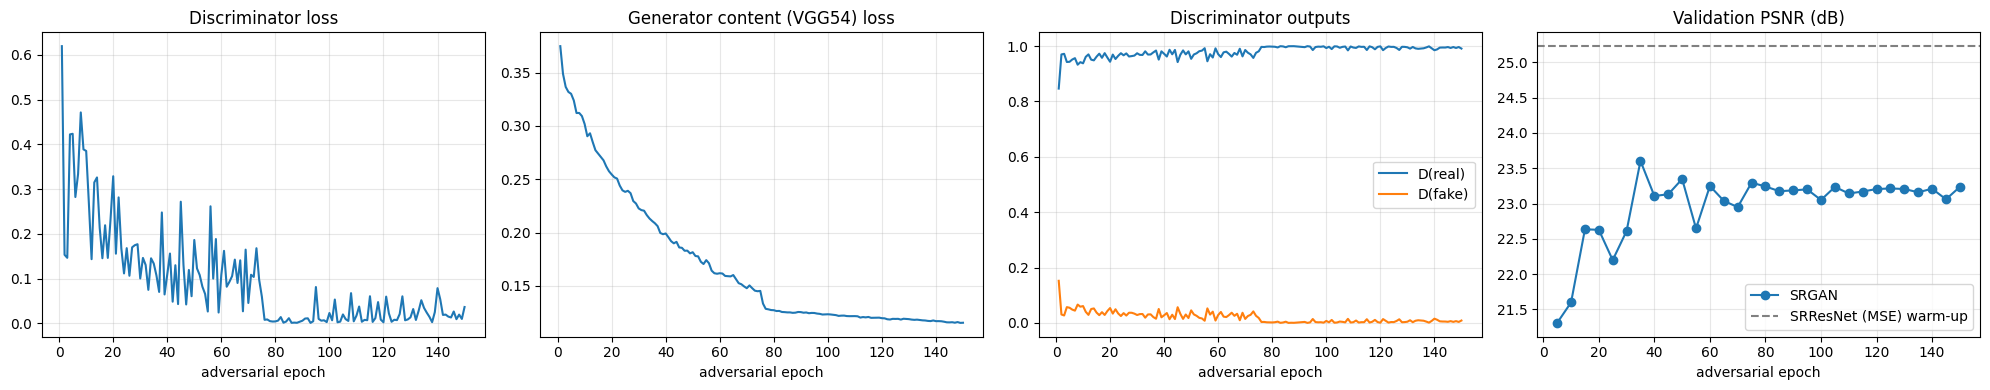

In [14]:
# ---------- SRGAN training curves ----------
gh = pd.DataFrame(state["gan_history"])
gh.to_csv(os.path.join(RESULTS_DIR, "srgan_training_log.csv"), index=False)
ph = pd.DataFrame(state["pretrain_history"])

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].plot(gh["epoch"], gh["d_loss"]); ax[0].set_title("Discriminator loss")
ax[1].plot(gh["epoch"], gh["content"], label="VGG54 content"); ax[1].set_title("Generator content (VGG54) loss")
ax[2].plot(gh["epoch"], gh["D_real"], label="D(real)"); ax[2].plot(gh["epoch"], gh["D_fake"], label="D(fake)")
ax[2].set_title("Discriminator outputs"); ax[2].legend()
if "val_psnr" in gh:
    v = gh.dropna(subset=["val_psnr"])
    ax[3].plot(v["epoch"], v["val_psnr"], "o-", label="SRGAN")
    if len(ph): ax[3].axhline(ph["val_psnr"].iloc[-1], color="gray", ls="--", label="SRResNet (MSE) warm-up")
    ax[3].set_title("Validation PSNR (dB)"); ax[3].legend()
for a in ax:
    a.set_xlabel("adversarial epoch"); a.grid(alpha=0.3)
plt.tight_layout(); savefig("04_srgan_training_curves.png"); plt.show()

## 11. Generate the SRGAN Dataset (32×32 → 128×128) and Check Image Quality

The trained generator turns the 32×32 version of **every** image (train, validation and test) into a 128×128 image. These generated images are the only thing Classifier B ever sees. They are cached for the session.

Quality on the 30% test split is reported with **PSNR** and **SSIM** (RGB, against the real 128×128 image) for SRGAN and for plain bicubic enlargement. The paper notes that SRGAN images often score *lower* on PSNR than MSE-trained methods while looking sharper; PSNR rewards blur.

In [15]:
assert state["gan_epochs_done"] >= SRGAN_EPOCHS, (
    f"SRGAN has only {state['gan_epochs_done']} of {SRGAN_EPOCHS} adversarial epochs — re-run §10 to finish training.")
generator.load_weights(os.path.join(MODEL_DIR, "srgan_generator.weights.h5"))
SR_CACHE = os.path.join(CACHE_DIR, f"srgan_images_{HR_SIZE}.npz")

def super_resolve(X_lr_uint8, batch=64):
    out = np.empty((len(X_lr_uint8), HR_SIZE, HR_SIZE, 3), np.uint8)
    for s in tqdm(range(0, len(X_lr_uint8), batch), desc="super-resolving"):
        sr = generate(to_lr_float(X_lr_uint8[s:s + batch])).numpy()
        out[s:s + batch] = np.clip((sr + 1.0) * 127.5, 0, 255).round().astype(np.uint8)
    return out

def bicubic_upscale(X_lr_uint8, batch=256):
    out = np.empty((len(X_lr_uint8), HR_SIZE, HR_SIZE, 3), np.uint8)
    for s in range(0, len(X_lr_uint8), batch):
        up = tf.image.resize(tf.cast(X_lr_uint8[s:s + batch], tf.float32), (HR_SIZE, HR_SIZE), method="bicubic")
        out[s:s + batch] = np.clip(up.numpy(), 0, 255).round().astype(np.uint8)
    return out

if os.path.exists(SR_CACHE) and state["gan_epochs_done"] == int(np.load(SR_CACHE)["gan_epochs"]):
    X_sr = np.load(SR_CACHE)["X_sr"]
    print("Loaded generated images from", SR_CACHE)
else:
    X_sr = super_resolve(X_lr)
    tmp = SR_CACHE + ".tmp.npz"
    np.savez(tmp, X_sr=X_sr, gan_epochs=state["gan_epochs_done"])
    os.replace(tmp, SR_CACHE)
    print("Saved generated images ->", SR_CACHE)

X_bicubic_test = bicubic_upscale(X_lr[test_idx])
print("SRGAN images:", X_sr.shape, X_sr.dtype)

def quality(pred_uint8, ref_uint8, batch=256):
    ps, ss = [], []
    for s in range(0, len(ref_uint8), batch):
        a = tf.cast(pred_uint8[s:s + batch], tf.float32) / 255.0
        b = tf.cast(ref_uint8[s:s + batch], tf.float32) / 255.0
        ps.append(tf.image.psnr(a, b, 1.0).numpy()); ss.append(tf.image.ssim(a, b, 1.0).numpy())
    return float(np.mean(np.concatenate(ps))), float(np.mean(np.concatenate(ss)))

q = pd.DataFrame([
    ["Bicubic (32×32 → 128×128)", *quality(X_bicubic_test, X_hr[test_idx])],
    ["SRGAN (32×32 → 128×128)",   *quality(X_sr[test_idx], X_hr[test_idx])],
], columns=["Method", "PSNR (dB)", "SSIM"])
q.to_csv(os.path.join(RESULTS_DIR, "sr_quality_test.csv"), index=False)
print(f"\nImage quality on the {len(test_idx):,} test images:")
q.round(4)

super-resolving:   0%|          | 0/390 [00:00<?, ?it/s]

Saved generated images -> /content/AppliedAI_Midterm_SRGAN/full_run/cache/srgan_images_128.npz
SRGAN images: (24930, 128, 128, 3) uint8

Image quality on the 7,479 test images:


,Method,PSNR (dB),SSIM
0,Bicubic (32×32 → 128×128),25.0594,0.7071
1,SRGAN (32×32 → 128×128),23.3882,0.6293


saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/05_srgan_test_examples.png


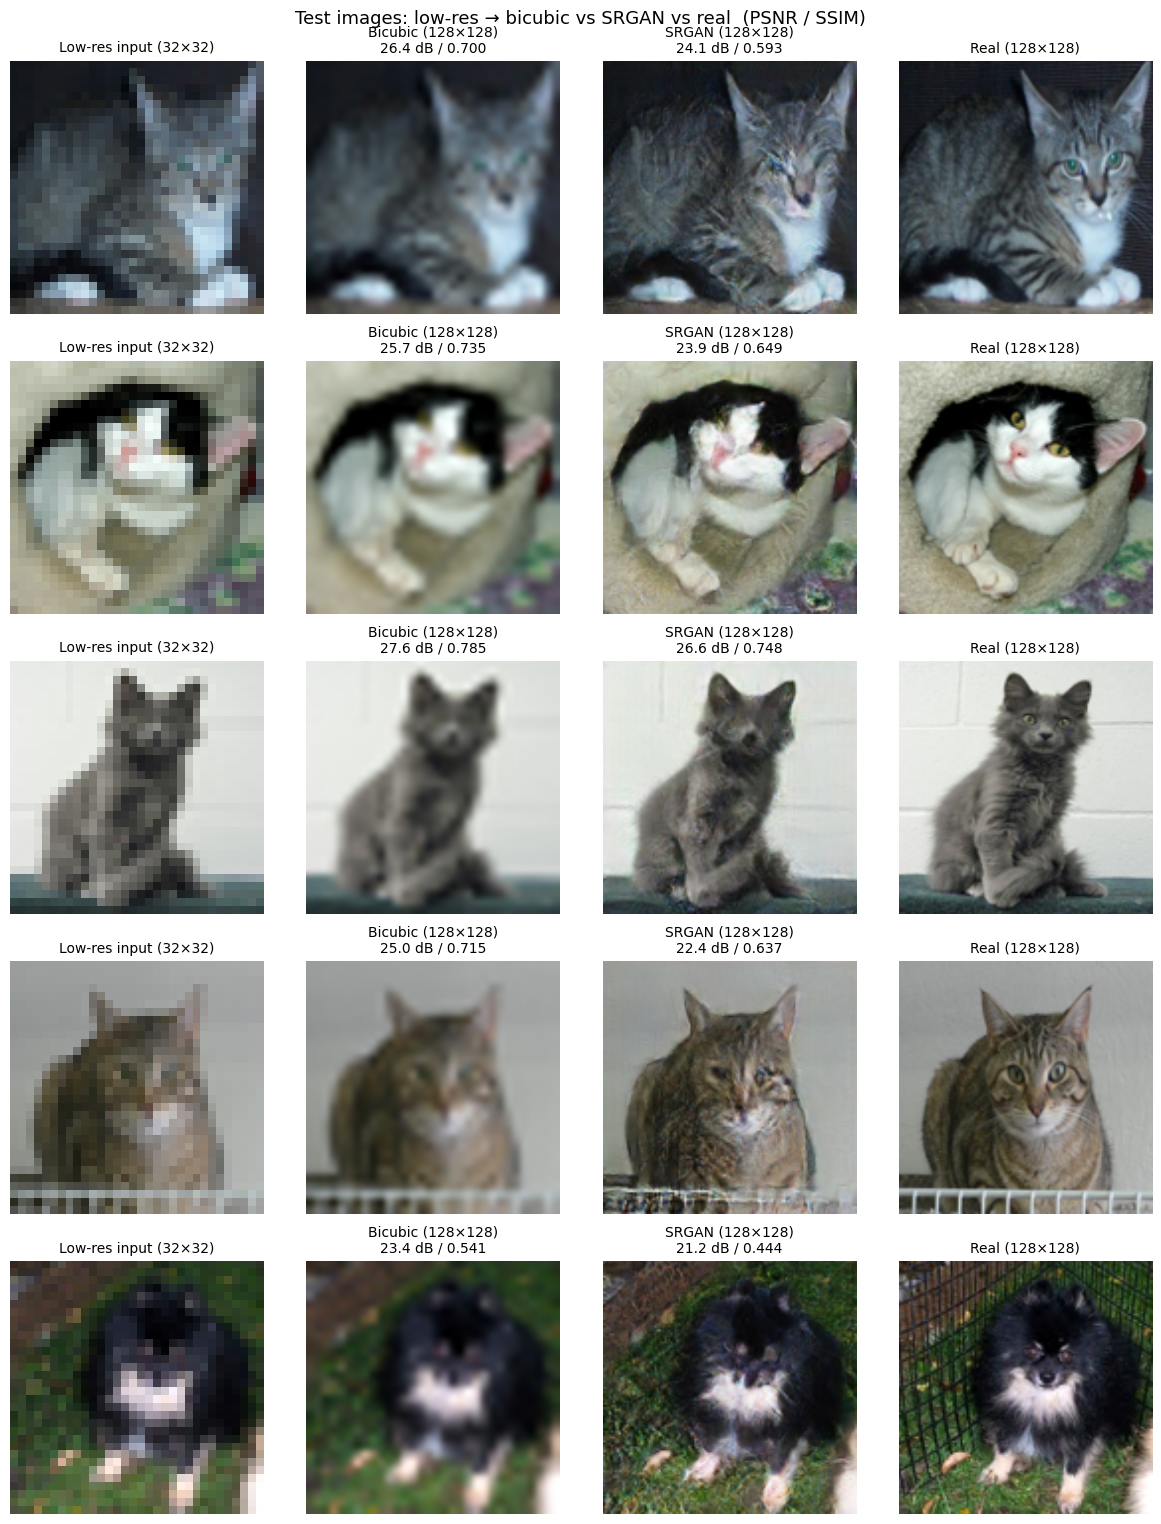

In [16]:
# ---------- visual comparison on test images ----------
rng = np.random.default_rng(7)
pick = rng.choice(test_idx, 5, replace=False)
fig, axes = plt.subplots(len(pick), 4, figsize=(12, 3.1 * len(pick)))
pos = {int(t): k for k, t in enumerate(test_idx)}
for r, i in enumerate(pick):
    bic = X_bicubic_test[pos[int(i)]]
    p_b, s_b = quality(bic[None], X_hr[i][None]); p_s, s_s = quality(X_sr[i][None], X_hr[i][None])
    panels = [(X_lr[i], f"Low-res input ({LR_SIZE}×{LR_SIZE})"),
              (bic, f"Bicubic ({HR_SIZE}×{HR_SIZE})\n{p_b:.1f} dB / {s_b:.3f}"),
              (X_sr[i], f"SRGAN ({HR_SIZE}×{HR_SIZE})\n{p_s:.1f} dB / {s_s:.3f}"),
              (X_hr[i], f"Real ({HR_SIZE}×{HR_SIZE})")]
    for c, (img, title) in enumerate(panels):
        axes[r, c].imshow(img, interpolation="nearest" if c == 0 else "bilinear")
        axes[r, c].set_title(title, fontsize=10); axes[r, c].axis("off")
plt.suptitle("Test images: low-res → bicubic vs SRGAN vs real  (PSNR / SSIM)", fontsize=13)
plt.tight_layout(); savefig("05_srgan_test_examples.png"); plt.show()

## 12. Classifier B — Same Recipe, Trained on SRGAN Images

Classifier B uses **the same architecture, hyper-parameters, augmentation, normalization and train/validation/test indices** as Classifier A. The only change is the input: every image is the SRGAN reconstruction of its 32×32 version.

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/06_classifier_inputs_A_vs_B.png


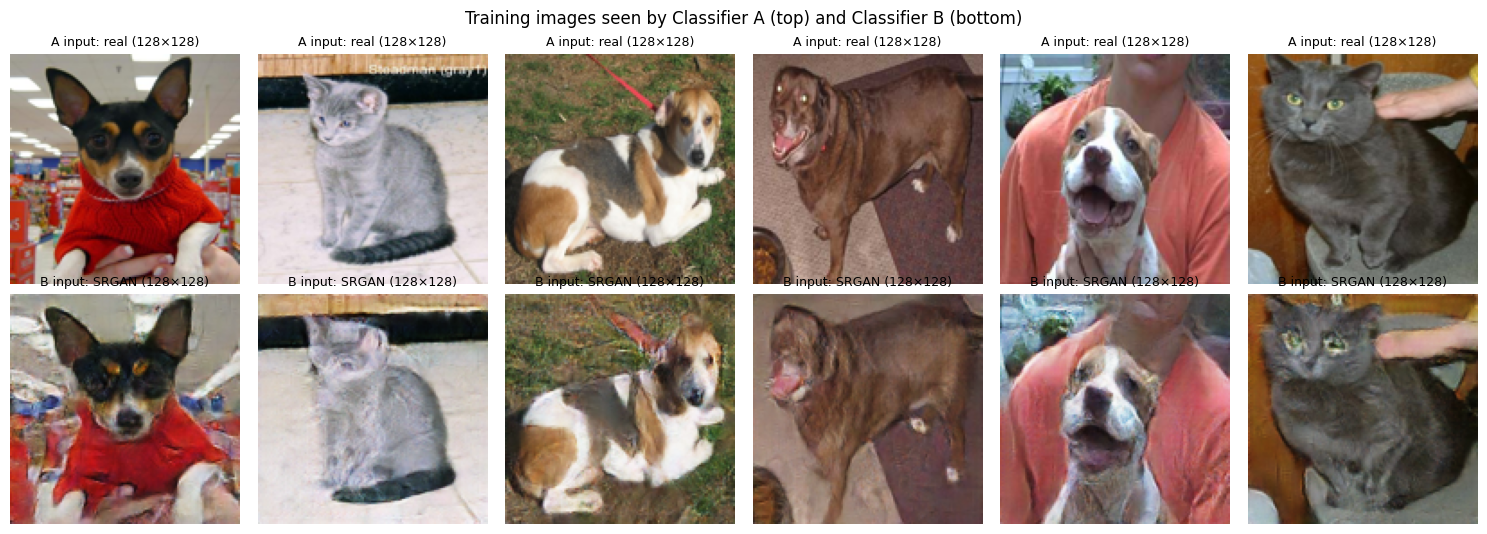


=== classifier_B: stage 1 — frozen MobileNetV2 ===
Epoch 1/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 79s 144ms/step - accuracy: 0.8927 - auc: 0.9629 - loss: 0.2468 - val_accuracy: 0.9330 - val_auc: 0.9875 - val_loss: 0.1588 - learning_rate: 0.0010
Epoch 2/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 63s 128ms/step - accuracy: 0.9180 - auc: 0.9757 - loss: 0.2003 - val_accuracy: 0.9439 - val_auc: 0.9885 - val_loss: 0.1388 - learning_rate: 0.0010
Epoch 3/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 61s 125ms/step - accuracy: 0.9239 - auc: 0.9777 - loss: 0.1911 - val_accuracy: 0.9456 - val_auc: 0.9885 - val_loss: 0.1398 - learning_rate: 0.0010
Epoch 4/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 62s 126ms/step - accuracy: 0.9273 - auc: 0.9801 - loss: 0.1797 - val_accuracy: 0.9467 - val_auc: 0.9889 - val_loss: 0.1364 - learning_rate: 2.0000e-04
Epoch 5/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 82s 125ms/step - accuracy: 0.9287 - auc: 0.9805 - loss: 0.1782 - val_accuracy: 0.9467 - val_auc: 0.9890 - val_loss: 0.1355 - learning_rate: 2.0000e-04
Trainable 

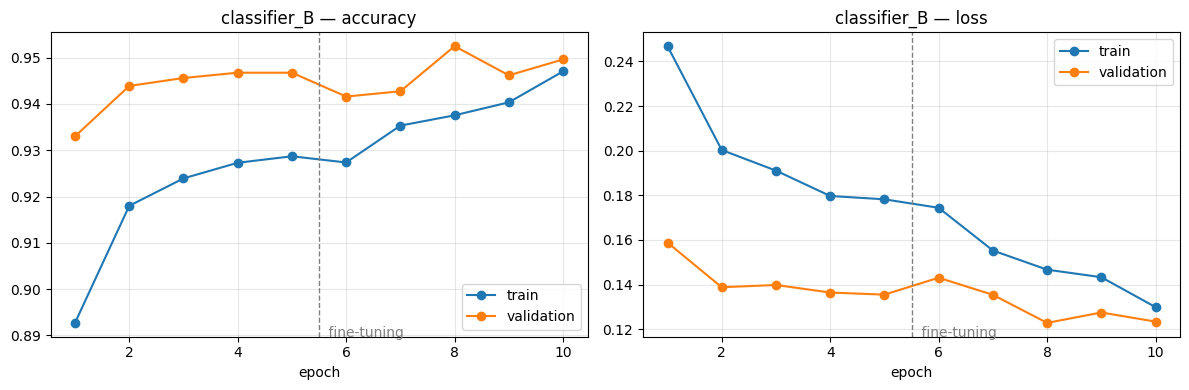

In [17]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for c, i in enumerate(train_idx[:6]):
    axes[0, c].imshow(X_hr[i]); axes[0, c].set_title(f"A input: real ({HR_SIZE}×{HR_SIZE})", fontsize=9)
    axes[1, c].imshow(X_sr[i]); axes[1, c].set_title(f"B input: SRGAN ({HR_SIZE}×{HR_SIZE})", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Training images seen by Classifier A (top) and Classifier B (bottom)")
plt.tight_layout(); savefig("06_classifier_inputs_A_vs_B.png"); plt.show()

clf_B, hist_B = train_classifier("classifier_B",
                                 X_sr[train_idx], y_all[train_idx],
                                 X_sr[val_idx], y_all[val_idx])
plot_clf_history(hist_B, "classifier_B")

## 13. Compare Classifier A and Classifier B

**Main comparison** (each model on the kind of image it was trained on):
* **A** on the real 128×128 test images
* **B** on the SRGAN-generated 128×128 test images

**Extra rows** (for discussion):
* A on SRGAN test images and B on real test images — how well each model transfers to the other kind of image
* A on bicubic test images — what happens with plain interpolation and no GAN

All metrics use a 0.5 decision threshold; AUC uses the predicted probabilities.

In [18]:
def predict_proba(model, X, batch=128):
    ds = tf.data.Dataset.from_tensor_slices(X).batch(batch).map(normalize).prefetch(AUTOTUNE)
    return model.predict(ds, verbose=0).ravel()

y_test = y_all[test_idx]
runs = {
    "A — real test (128×128)":           (clf_A, X_hr[test_idx]),
    "B — SRGAN test (128×128)":          (clf_B, X_sr[test_idx]),
    "A — SRGAN test (cross)":            (clf_A, X_sr[test_idx]),
    "B — real test (cross)":             (clf_B, X_hr[test_idx]),
    "A — bicubic test (reference)":      (clf_A, X_bicubic_test),
}
probs, rows = {}, []
for name, (model, X) in runs.items():
    p = predict_proba(model, X); probs[name] = p
    pred = (p >= 0.5).astype(int)
    rows.append({"Model / test images": name,
                 "Accuracy":  accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall":    recall_score(y_test, pred),
                 "F1":        f1_score(y_test, pred),
                 "AUC":       roc_auc_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model / test images")
results.loc["B − A (main comparison)"] = results.loc["B — SRGAN test (128×128)"] - results.loc["A — real test (128×128)"]
results.to_csv(os.path.join(RESULTS_DIR, "classifier_comparison.csv"))

# per-image predictions and every setting of this run, for the report / reproducibility
pd.DataFrame({"file": [os.path.basename(str(p)) for p in paths[test_idx]], "true_label": y_test,
              "A_prob_dog_real": probs["A — real test (128×128)"],
              "B_prob_dog_srgan": probs["B — SRGAN test (128×128)"]}
             ).to_csv(os.path.join(RESULTS_DIR, "test_predictions.csv"), index=False)
run_params = dict(dataset=KAGGLE_DATASET, seed=SEED, images=int(len(y_all)), train=int(len(train_idx)),
                  val=int(len(val_idx)), test=int(len(test_idx)), hr_size=HR_SIZE, lr_size=LR_SIZE,
                  srgan_train_images=int(len(srgan_idx)), res_blocks=NUM_RES_BLOCKS, srgan_batch=SRGAN_BATCH,
                  pretrain_epochs=state["pretrain_epochs_done"], gan_epochs=state["gan_epochs_done"],
                  adv_weight=ADV_WEIGHT, content_loss="VGG54 (block5_conv4) / 12.75",
                  clf_epochs=[INITIAL_EPOCHS, FINE_TUNE_EPOCHS], tensorflow=tf.__version__, keras=keras.__version__,
                  gpu=[d.name for d in tf.config.list_physical_devices("GPU")])
with open(os.path.join(RESULTS_DIR, "run_parameters.json"), "w") as f:
    json.dump(run_params, f, indent=2)
results.round(4)

,Accuracy,Precision,Recall,F1,AUC
Model / test images,,,,,
A — real test (128×128),0.9803,0.9779,0.9829,0.9804,0.9980
B — SRGAN test (128×128),0.9362,0.9205,0.9548,0.9373,0.9862
A — SRGAN test (cross),0.9318,0.9138,0.9534,0.9332,0.9839
B — real test (cross),0.9775,0.9717,0.9837,0.9777,0.9979
A — bicubic test (reference),0.8850,0.9586,0.8047,0.8749,0.9660
B − A (main comparison),-0.0441,-0.0574,-0.0281,-0.0430,-0.0118


 A — real test (128×128) 
              precision    recall  f1-score   support

         Cat     0.9828    0.9778    0.9803      3742
         Dog     0.9779    0.9829    0.9804      3737

    accuracy                         0.9803      7479
   macro avg     0.9804    0.9803    0.9803      7479
weighted avg     0.9804    0.9803    0.9803      7479

 B — SRGAN test (128×128) 
              precision    recall  f1-score   support

         Cat     0.9531    0.9177    0.9351      3742
         Dog     0.9205    0.9548    0.9373      3737

    accuracy                         0.9362      7479
   macro avg     0.9368    0.9362    0.9362      7479
weighted avg     0.9368    0.9362    0.9362      7479

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/07_confusion_matrices.png


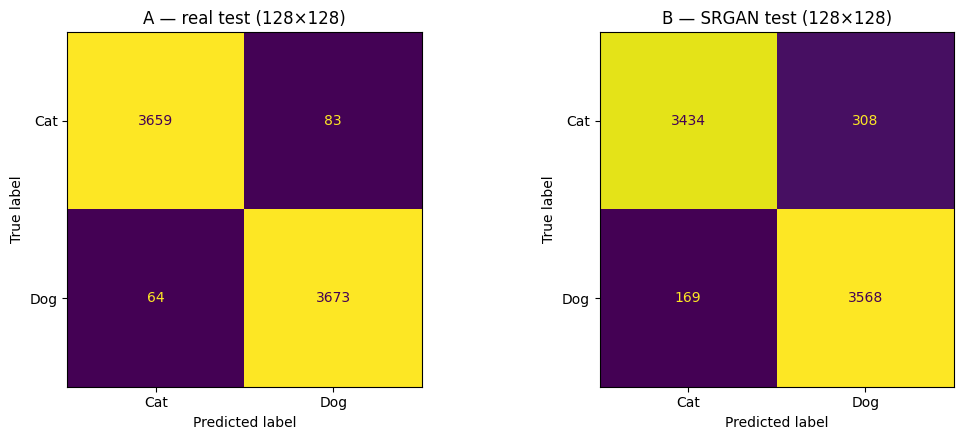

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/08_roc_curves.png


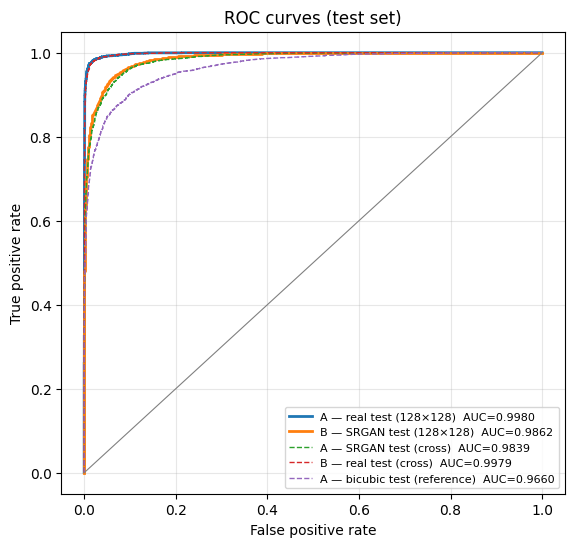

saved -> /content/AppliedAI_Midterm_SRGAN/full_run/results/09_metric_comparison.png


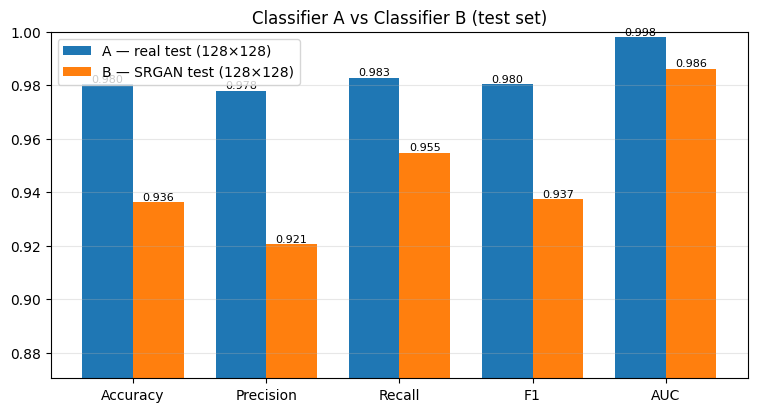

In [19]:
main = ["A — real test (128×128)", "B — SRGAN test (128×128)"]
for name in main:
    print("=" * 60, "\n", name, "\n", "=" * 60)
    print(classification_report(y_test, (probs[name] >= 0.5).astype(int), target_names=CLASS_NAMES, digits=4))

# ---- confusion matrices ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for a, name in zip(axes, main):
    cm = confusion_matrix(y_test, (probs[name] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=a, colorbar=False, values_format="d")
    a.set_title(name)
plt.tight_layout(); savefig("07_confusion_matrices.png"); plt.show()

# ---- ROC curves ----
plt.figure(figsize=(6.5, 6))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2 if name in main else 1, ls="-" if name in main else "--",
             label=f"{name}  AUC={roc_auc_score(y_test, p):.4f}")
plt.plot([0, 1], [0, 1], color="gray", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)")
plt.legend(fontsize=8, loc="lower right"); plt.grid(alpha=0.3)
savefig("08_roc_curves.png"); plt.show()

# ---- metric bar chart (main comparison) ----
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
x = np.arange(len(metrics)); w = 0.38
plt.figure(figsize=(9, 4.5))
for k, name in enumerate(main):
    vals = results.loc[name, metrics].values
    bars = plt.bar(x + (k - 0.5) * w, vals, w, label=name)
    plt.bar_label(bars, fmt="%.3f", fontsize=8)
lo = max(0.0, results.loc[main, metrics].values.min() - 0.05)
plt.ylim(lo, 1.0); plt.xticks(x, metrics); plt.title("Classifier A vs Classifier B (test set)")
plt.legend(); plt.grid(axis="y", alpha=0.3)
savefig("09_metric_comparison.png"); plt.show()

## 14. Write the Results Summary for the README

This cell writes `results/results_summary.md` with the numbers from this run, ready to paste into the README's *Results* section, and copies the final models and figures to `/content/repo_export/` for upload to GitHub.

In [20]:
def md_table(df, digits=4):
    cols = [df.index.name or ""] + list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) else str(v) for v in row]) + " |")
    return "\n".join(lines)

A, B = results.loc[main[0]], results.loc[main[1]]
summary = f'''## Results (generated by the notebook)

**Data:** {len(y_all):,} images ({(y_all==0).sum():,} cats, {(y_all==1).sum():,} dogs) → train {len(train_idx):,} / validation {len(val_idx):,} / test {len(test_idx):,}  (70% / 30% split, validation taken from the 70%).
**SRGAN:** {state["pretrain_epochs_done"]} SRResNet warm-up epochs + {state["gan_epochs_done"]} adversarial epochs on {len(srgan_idx):,} training images (32×32 → 128×128).

### Super-resolution quality on the test set (128×128)
{md_table(q.set_index("Method"))}

### Classifier comparison on the test set
{md_table(results)}

**Accuracy:** A {A["Accuracy"]:.4f} vs B {B["Accuracy"]:.4f} (difference {100*(B["Accuracy"]-A["Accuracy"]):+.2f} percentage points)
**F1:** A {A["F1"]:.4f} vs B {B["F1"]:.4f}
**AUC:** A {A["AUC"]:.4f} vs B {B["AUC"]:.4f}
'''
with open(os.path.join(RESULTS_DIR, "results_summary.md"), "w") as f:
    f.write(summary)
print(summary)

# ---- export everything the GitHub repo needs ----
EXPORT = "/content/repo_export" if IN_COLAB else os.path.abspath("./repo_export")
os.makedirs(os.path.join(EXPORT, "models"), exist_ok=True)
shutil.copytree(RESULTS_DIR, os.path.join(EXPORT, "results"), dirs_exist_ok=True)
for fname in ["srgan_generator.weights.h5", "classifier_A.keras", "classifier_B.keras"]:
    shutil.copy(os.path.join(MODEL_DIR, fname), os.path.join(EXPORT, "models", fname))
shutil.make_archive(EXPORT, "zip", EXPORT)
print("Repo export ->", EXPORT + ".zip")
for p in sorted(Path(EXPORT).rglob("*")):
    if p.is_file(): print(f"  {p.relative_to(EXPORT)}  ({p.stat().st_size/1e6:.1f} MB)")

## Results (generated by the notebook)

**Data:** 24,930 images (12,472 cats, 12,458 dogs) → train 15,705 / validation 1,746 / test 7,479  (70% / 30% split, validation taken from the 70%).
**SRGAN:** 10 SRResNet warm-up epochs + 150 adversarial epochs on 5,000 training images (32×32 → 128×128).

### Super-resolution quality on the test set (128×128)
| Method | PSNR (dB) | SSIM |
|---|---|---|
| Bicubic (32×32 → 128×128) | 25.0594 | 0.7071 |
| SRGAN (32×32 → 128×128) | 23.3882 | 0.6293 |

### Classifier comparison on the test set
| Model / test images | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| A — real test (128×128) | 0.9803 | 0.9779 | 0.9829 | 0.9804 | 0.9980 |
| B — SRGAN test (128×128) | 0.9362 | 0.9205 | 0.9548 | 0.9373 | 0.9862 |
| A — SRGAN test (cross) | 0.9318 | 0.9138 | 0.9534 | 0.9332 | 0.9839 |
| B — real test (cross) | 0.9775 | 0.9717 | 0.9837 | 0.9777 | 0.9979 |
| A — bicubic test (reference) | 0.8850 | 0.9586 | 0.8047 | 0.8749 | 0.9660 |
| B 

In [21]:
# Download the export (models + figures + CSVs) to your computer, then add it to the GitHub repo.
if IN_COLAB:
    from google.colab import files
    files.download("/content/repo_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Download the Resume Backup (run any time)

Without Google Drive, run this before your Colab session ends (or download `srgan_backup.zip` from the Files panel). Next session: upload it to `/content`, then *Run all*.

In [22]:
make_backup()
if IN_COLAB:
    from google.colab import files
    files.download(BACKUP_ZIP)

  backup refreshed -> /content/srgan_backup.zip (586 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Conclusion

**Results on the 7,479 test images (30% split):**

| Model / test images | Accuracy | F1 | AUC |
|---|---|---|---|
| A — real images (128×128) | 0.9803 | 0.9804 | 0.9980 |
| B — SRGAN images (128×128) | 0.9362 | 0.9373 | 0.9862 |
| A — bicubic images (reference) | 0.8850 | 0.8749 | 0.9660 |

* **B vs A:** Classifier B, trained only on images the SRGAN rebuilt from 32×32 inputs, reaches 93.6% accuracy, 4.4 points below Classifier A on the real images. The 32×32 images lose information the SRGAN cannot fully recover. Most of B's extra errors are cats predicted as dogs (308 vs 83).
* **SRGAN vs bicubic:** SRGAN scores lower on pixel metrics (PSNR 23.39 vs 25.06 dB, SSIM 0.629 vs 0.707), as the paper also reports for GAN-based super-resolution. For classification it is clearly better: Classifier A scores 93.2% on SRGAN images vs 88.5% on bicubic images. The GAN restores texture and edges (fur, whiskers, outlines) that the classifier uses, while bicubic output is blurry.
* **Cross tests:** B on real photos scores 97.8%, almost equal to A. Training on generated images did not hurt performance on real images. A on SRGAN images scores 93.2%, close to B's 93.6%, so the gap comes mainly from lost information, not from a train/test mismatch.
* **Training:** the VGG54 content loss fell steadily over 150 adversarial epochs, with a clear drop when the learning rate changed at epoch 76. The discriminator stayed dominant (D(real) ≈ 0.99, D(fake) ≈ 0.01), which is typical with the paper's small 10⁻³ adversarial weight.

**Limitations:** the SRGAN trained on a 5,000-image subset for ~47k updates (paper: 2×10⁵); single random seed; PSNR/SSIM on RGB rather than the Y channel; short 5 + 5 epoch classifier schedule.